# ApacheJIT Exploratory Data Analysis

This notebook analyzes the actual ApacheJIT training CSV. No records are removed during exploratory analysis.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd().resolve()
project_root = next(
    (path for path in [current, *current.parents]
     if (path / 'data' / 'raw' / 'apachejit_train.csv').exists()),
    current,
)
raw_path = project_root / 'data' / 'raw' / 'apachejit_train.csv'
figures = project_root / 'reports' / 'figures'
figures.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(raw_path)
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (44834, 18)


,commit_id,project,buggy,fix,year,author_date,la,ld,nf,nd,ns,ent,ndev,age,nuc,aexp,arexp,asexp
0,06a456ec1670fb26a86f8a18f5b55017ac961f39,apache/groovy,True,False,2003,1064916954,223,33,7,5,2,2.213687,0.142857,1.857143,12.142857,104,104.0,0.000606
1,79f50a10e7688279664146bb3c18837dada370a4,apache/groovy,False,False,2003,1071086882,138,10,9,3,1,1.692477,0.333333,32.333333,11.777778,287,287.0,228.000000
2,42437917f185f8efa3d947fae3bb08b584504650,apache/groovy,False,False,2003,1072801387,69,20,2,2,1,0.599911,1.500000,9.500000,16.500000,366,366.0,281.000000
3,b6616e5fb6d537229d307cf8647ef483468175a6,apache/groovy,True,False,2003,1072694298,52,2,2,2,1,0.380947,1.000000,6.000000,14.000000,364,364.0,279.000000
4,5d0abaebf0bd4b5d98f9ef173f23b3be5e6fb37f,apache/groovy,True,False,2003,1070542250,256,348,8,4,1,0.489213,0.375000,13.625000,20.000000,253,253.0,199.000000


## 1. Dataset overview and data types

In [2]:
print('Dimensions:', df.shape)
print('Columns:', df.columns.tolist())
print(df.dtypes.to_string())

Dimensions: (44834, 18)
Columns: ['commit_id', 'project', 'buggy', 'fix', 'year', 'author_date', 'la', 'ld', 'nf', 'nd', 'ns', 'ent', 'ndev', 'age', 'nuc', 'aexp', 'arexp', 'asexp']
commit_id          str
project            str
buggy             bool
fix               bool
year             int64
author_date      int64
la               int64
ld               int64
nf               int64
nd               int64
ns               int64
ent            float64
ndev           float64
age            float64
nuc            float64
aexp             int64
arexp          float64
asexp          float64


## 2. Missing values

In [3]:
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)
missing = pd.DataFrame({'missing_count': missing_count, 'missing_percent': missing_percent})
print(missing.to_string())
missing_plot = missing[missing['missing_count'] > 0]
if not missing_plot.empty:
    ax = missing_plot['missing_count'].plot(kind='bar', figsize=(10, 4), title='Missing values by column')
    ax.set_ylabel('Missing count')
    plt.tight_layout()
    plt.savefig(figures / 'missing_values.png', dpi=150, bbox_inches='tight')
    plt.show()

             missing_count  missing_percent
commit_id                0              0.0
project                  0              0.0
buggy                    0              0.0
fix                      0              0.0
year                     0              0.0
author_date              0              0.0
la                       0              0.0
ld                       0              0.0
nf                       0              0.0
nd                       0              0.0
ns                       0              0.0
ent                      0              0.0
ndev                     0              0.0
age                      0              0.0
nuc                      0              0.0
aexp                     0              0.0
arexp                    0              0.0
asexp                    0              0.0


## 3. Duplicate analysis

In [4]:
duplicate_count = int(df.duplicated().sum())
print('Duplicate records:', duplicate_count)

Duplicate records: 0


## 4. Target class distribution

buggy
True     22421
False    22413
Name: count, dtype: int64


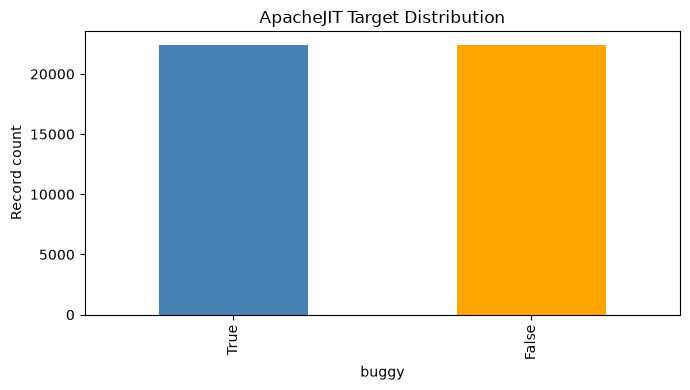

In [5]:
target_counts = df['buggy'].value_counts(dropna=False)
print(target_counts)
ax = target_counts.plot(kind='bar', color=['steelblue', 'orange'], figsize=(7, 4), title='ApacheJIT Target Distribution')
ax.set_xlabel('buggy')
ax.set_ylabel('Record count')
plt.tight_layout()
plt.savefig(figures / 'target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Numerical feature distributions

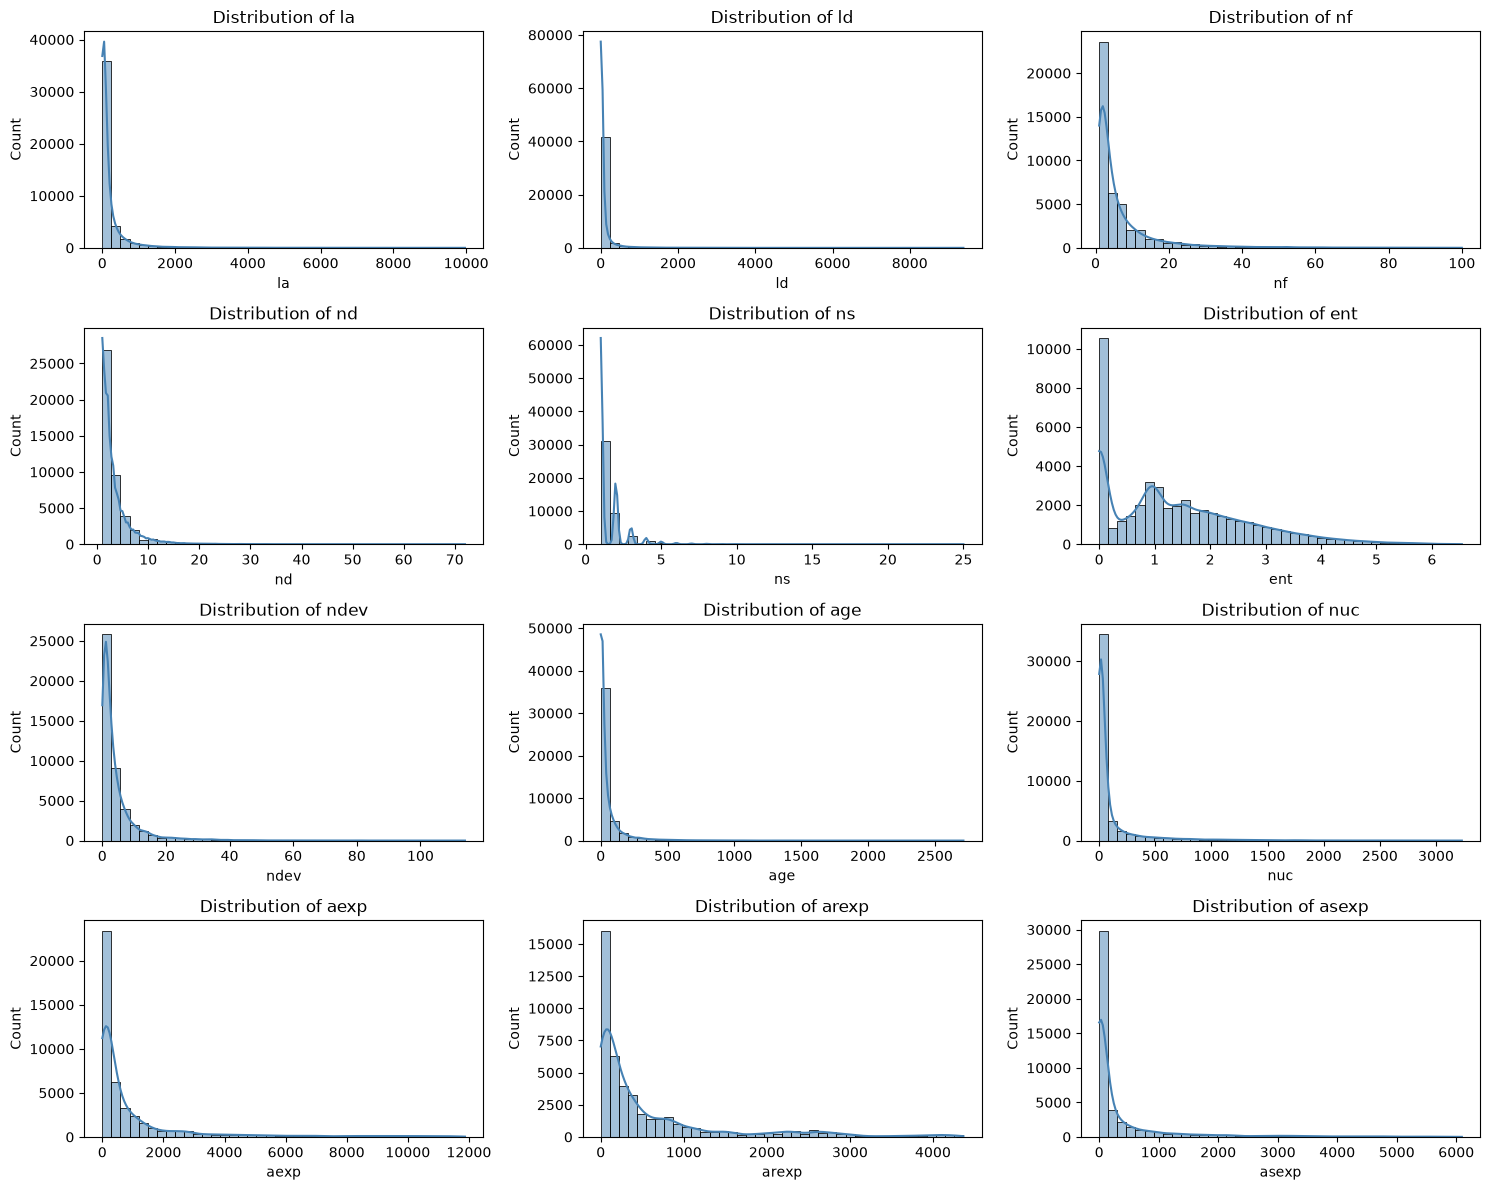

In [6]:
feature_columns = ['la', 'ld', 'nf', 'nd', 'ns', 'ent', 'ndev', 'age', 'nuc', 'aexp', 'arexp', 'asexp']
feature_columns = [column for column in feature_columns if column in df.columns]
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()
for index, column in enumerate(feature_columns):
    sns.histplot(df[column].dropna(), bins=40, ax=axes[index], kde=True, color='steelblue')
    axes[index].set_title(f'Distribution of {column}')
plt.tight_layout()
plt.savefig(figures / 'feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Outlier investigation

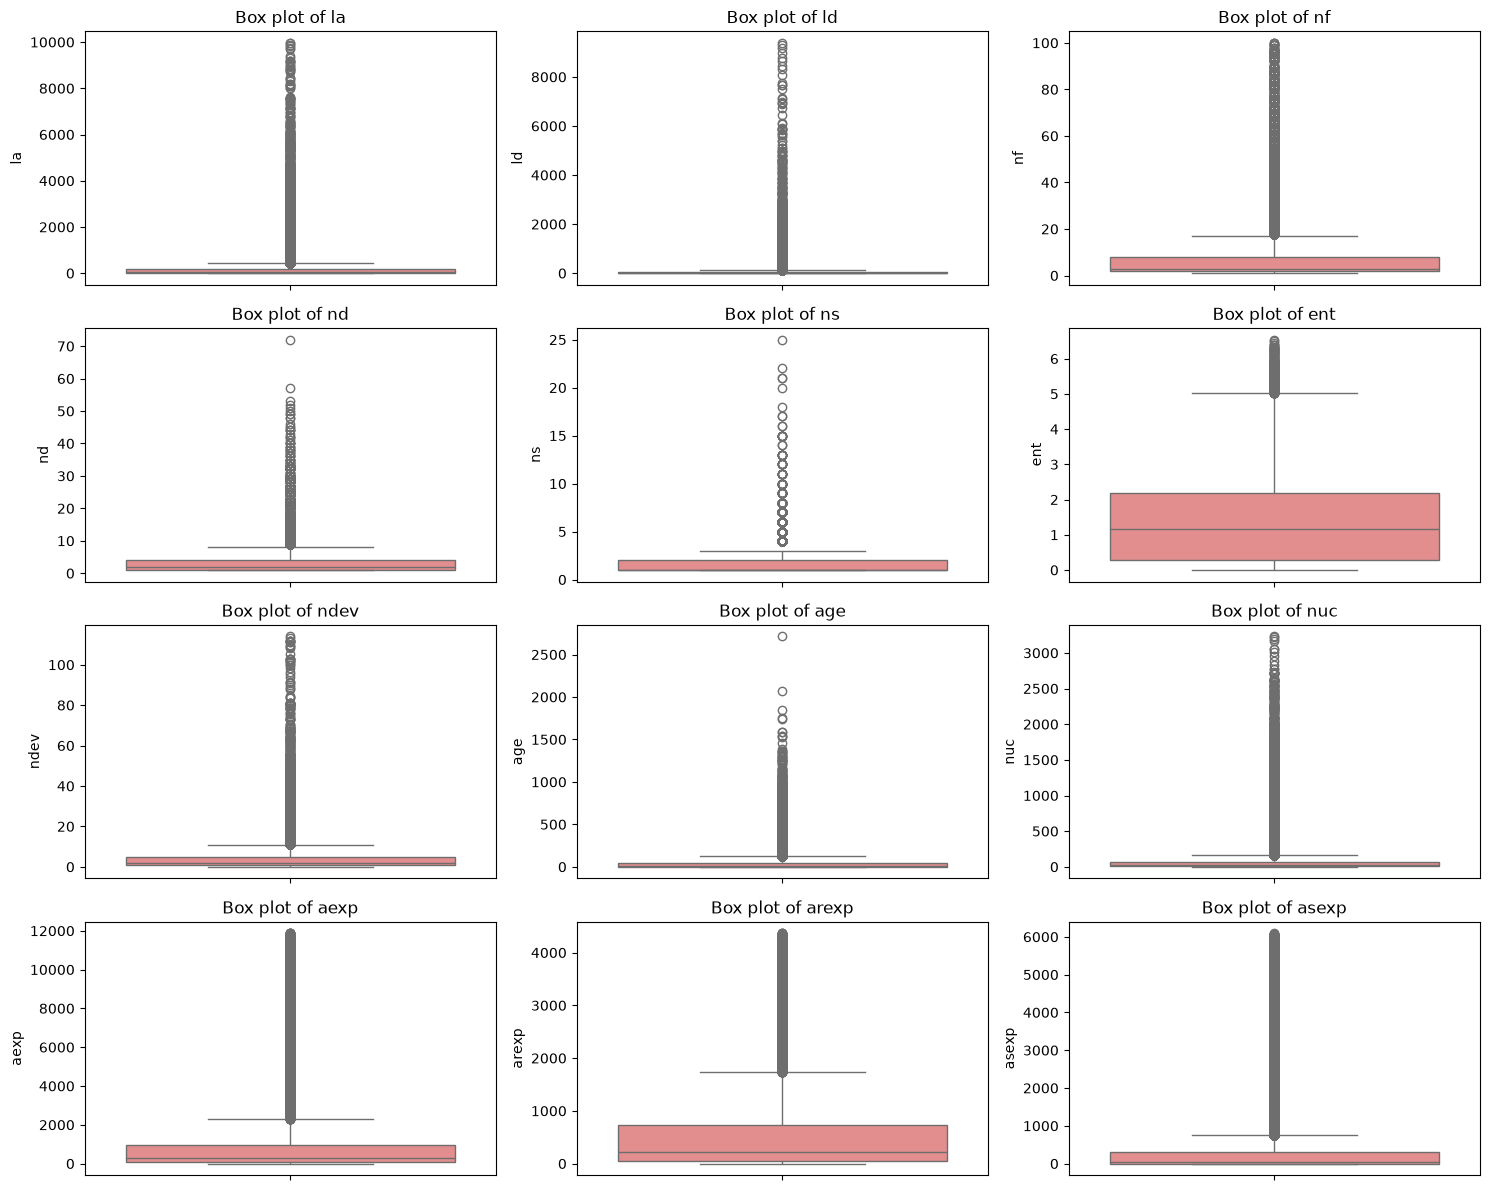

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
axes = axes.flatten()
for index, column in enumerate(feature_columns):
    sns.boxplot(y=df[column].dropna(), ax=axes[index], color='lightcoral')
    axes[index].set_title(f'Box plot of {column}')
plt.tight_layout()
plt.savefig(figures / 'feature_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Feature correlation analysis

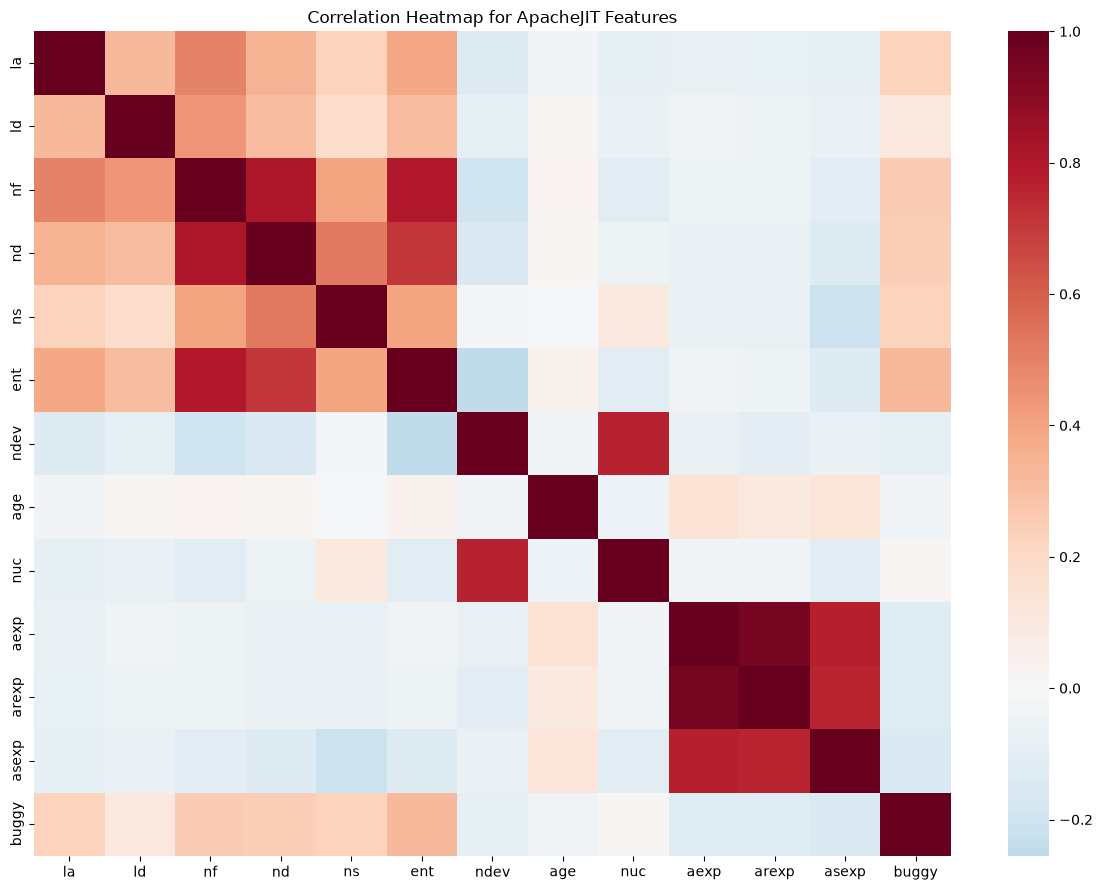

In [8]:
correlation_columns = feature_columns + (['buggy'] if 'buggy' in df.columns else [])
correlation = df[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=False, cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap for ApacheJIT Features')
plt.tight_layout()
plt.savefig(figures / 'correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Important observations and conclusions

The conclusions below are limited to what is visible in the actual dataset:

- Report the printed dimensions, missing values, duplicate count, and target counts rather than assuming additional findings.
- Wide feature ranges and boxplots show that several change metrics include extreme values; no automatic outlier removal was performed.
- The correlation heatmap displays relationships among available numerical features and should not be interpreted as causation.
- Commit identifiers, project/time metadata, and the target are not appropriate as the simple model feature list.